<a href="https://colab.research.google.com/github/Thorfinn-009/Smart-Helmet-Detection-YOLOv8/blob/main/Helmet_Detection_Milestone_2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#

In [46]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All"
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/bike-helmets-detection/annotations/BikesHelmets338.xml
/kaggle/input/bike-helmets-detection/annotations/BikesHelmets680.xml
/kaggle/input/bike-helmets-detection/annotations/BikesHelmets62.xml
/kaggle/input/bike-helmets-detection/annotations/BikesHelmets172.xml
/kaggle/input/bike-helmets-detection/annotations/BikesHelmets622.xml
/kaggle/input/bike-helmets-detection/annotations/BikesHelmets477.xml
/kaggle/input/bike-helmets-detection/annotations/BikesHelmets488.xml
/kaggle/input/bike-helmets-detection/annotations/BikesHelmets696.xml
/kaggle/input/bike-helmets-detection/annotations/BikesHelmets71.xml
/kaggle/input/bike-helmets-detection/annotations/BikesHelmets269.xml
/kaggle/input/bike-helmets-detection/annotations/BikesHelmets206.xml
/kaggle/input/bike-helmets-detection/annotations/BikesHelmets705.xml
/kaggle/input/bike-helmets-detection/annotations/BikesHelmets515.xml
/kaggle/input/bike-helmets-detection/annotations/BikesHelmets113.xml
/kaggle/input/bike-helmets-detection

In [47]:

import torch

print("GPU Available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU Name:", torch.cuda.get_device_name(0))


GPU Available: False


In [48]:

import os

# Display available datasets in Kaggle
dataset_path = "/kaggle/input"

print("Available datasets:")
for dataset in os.listdir(dataset_path):
    print("📁", dataset)


Available datasets:
📁 bike-helmets-detection


In [49]:

import os

# Find dataset files and folders
for root, dirs, files in os.walk("/kaggle/input/datasets"):
    print("Folder:", root)
    print("Subfolders:", dirs)
    print("Files:", files[:10])
    print("-" * 50)

    # Limit output to avoid too much text
    if root.count("/") >= 6:
        dirs[:] = []


In [50]:
import os
import yaml

# Verified dataset and configuration paths
WORKING_PATH = "/kaggle/working/helmet_dataset"
CONFIG_PATH = "/kaggle/working/helmet_data.yaml"

# If the YAML config does not exist yet, generate it now using verified paths
if not os.path.exists(CONFIG_PATH):
    print("Configuration file not found. Generating a new one...")
    dataset_config = {
        "path": WORKING_PATH,
        "train": "train/images",
        "val": "valid/images",
        "test": "test/images",
        "nc": 3,
        "names": [
            "With Helmet",
            "Without Helmet",
            "licence"
        ]
    }
    os.makedirs(os.path.dirname(CONFIG_PATH), exist_ok=True)
    with open(CONFIG_PATH, "w") as file:
        yaml.safe_dump(dataset_config, file, sort_keys=False)

# Read the confirmed configuration
with open(CONFIG_PATH, "r") as file:
    data = yaml.safe_load(file)

print("\nDATASET CONFIGURATION")
print("=" * 40)
print("Number of classes:", data.get("nc"))
print("Class names:", data.get("names"))

print("\nTraining path:", data.get("train"))
print("Validation path:", data.get("val"))
print("Testing path:", data.get("test"))

print("\nComplete YAML configuration:")
print(data)


DATASET CONFIGURATION
Number of classes: 3
Class names: ['With Helmet', 'Without Helmet', 'licence']

Training path: train/images
Validation path: valid/images
Testing path: test/images

Complete YAML configuration:
{'path': '/kaggle/working/helmet_dataset', 'train': 'train/images', 'val': 'valid/images', 'test': 'test/images', 'nc': 3, 'names': ['With Helmet', 'Without Helmet', 'licence']}


TRAIN
Images: 534
Label files: 534
------------------------------
VALID
Images: 153
Label files: 153
------------------------------
TEST
Images: 77
Label files: 77
------------------------------
Total images: 764


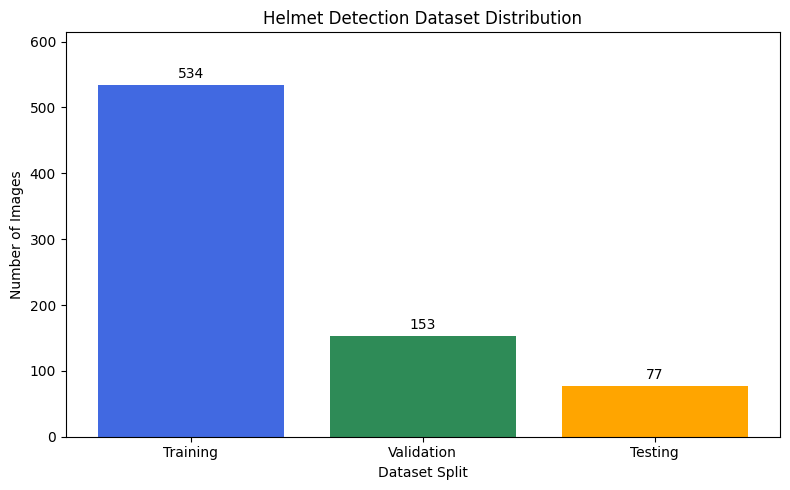

In [54]:
import os
import matplotlib.pyplot as plt

# Point to our verified and structured working dataset location
DATASET_PATH = "/kaggle/working/helmet_dataset"

# Count images and label files
splits = ["train", "valid", "test"]
image_counts = []
label_counts = []

if not os.path.exists(DATASET_PATH):
    print(f"Warning: Dataset path '{DATASET_PATH}' does not exist. Please run cell y6EXO41fsI5p first.")
else:
    for split in splits:
        image_folder = os.path.join(DATASET_PATH, split, "images")
        label_folder = os.path.join(DATASET_PATH, split, "labels")

        images = [
            f for f in os.listdir(image_folder)
            if f.lower().endswith((".jpg", ".jpeg", ".png"))
        ]

        labels = [
            f for f in os.listdir(label_folder)
            if f.endswith(".txt")
        ]

        image_counts.append(len(images))
        label_counts.append(len(labels))

        print(f"{split.upper()}")
        print(f"Images: {len(images)}")
        print(f"Label files: {len(labels)}")
        print("-" * 30)

    print("Total images:", sum(image_counts))

    # Visualise the dataset distribution
    plt.figure(figsize=(8, 5))
    bars = plt.bar(
        ["Training", "Validation", "Testing"],
        image_counts,
        color=["royalblue", "seagreen", "orange"]
    )

    plt.title("Helmet Detection Dataset Distribution")
    plt.xlabel("Dataset Split")
    plt.ylabel("Number of Images")

    for bar in bars:
        height = bar.get_height()
        plt.text(
            bar.get_x() + bar.get_width() / 2,
            height + 10,
            str(int(height)),
            ha="center"
        )

    plt.ylim(0, max(image_counts) * 1.15)
    plt.tight_layout()
    plt.savefig(
        "/kaggle/working/dataset_distribution.png",
        dpi=300
    )
    plt.show()

Found 534 images in training folder. Displaying the first few...


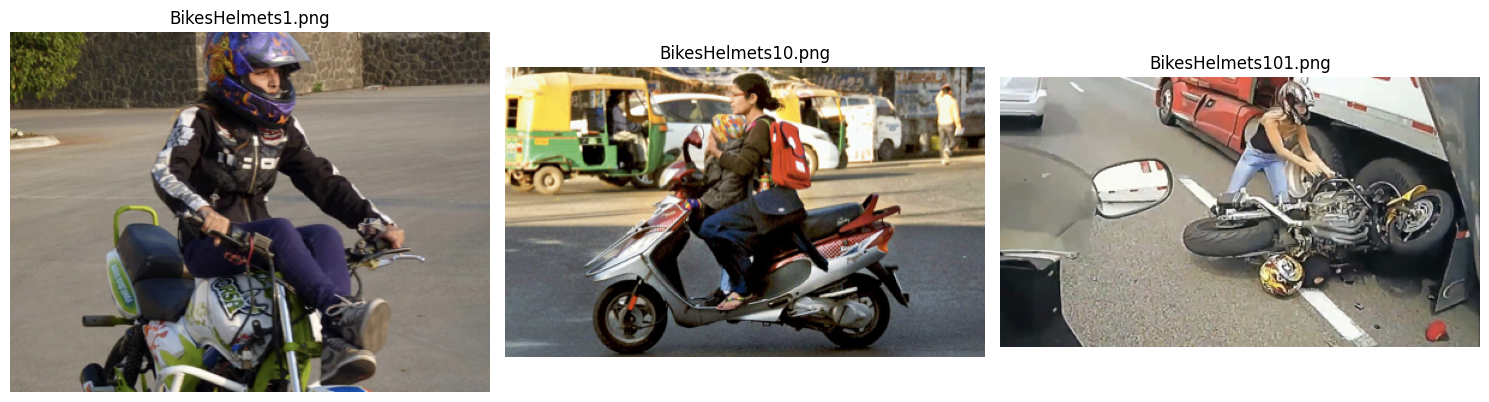

In [55]:
import os
import cv2
import matplotlib.pyplot as plt

# Verified training images path
train_image_dir = "/kaggle/working/helmet_dataset/train/images"

# Ensure directory exists and check its files
if os.path.exists(train_image_dir):
    images = sorted([
        f for f in os.listdir(train_image_dir)
        if f.lower().endswith((".jpg", ".jpeg", ".png"))
    ])

    if images:
        print(f"Found {len(images)} images in training folder. Displaying the first few...")
        # Select up to 3 images to show
        sample_images = images[:3]

        fig, axes = plt.subplots(1, len(sample_images), figsize=(15, 5))
        if len(sample_images) == 1:
            axes = [axes]

        for ax, img_name in zip(axes, sample_images):
            img_path = os.path.join(train_image_dir, img_name)
            img = cv2.imread(img_path)
            img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

            ax.imshow(img_rgb)
            ax.set_title(img_name)
            ax.axis("off")

        plt.tight_layout()
        plt.show()
    else:
        print(f"No images found in {train_image_dir}")
else:
    print(f"Training directory does not exist yet: {train_image_dir}. Please make sure you run the cell that copies the dataset (cell y6EXO41fsI5p) first!")


TRAIN CLASS DISTRIBUTION
With Helmet: 652
Without Helmet: 372
licence: 0

VALID CLASS DISTRIBUTION
With Helmet: 204
Without Helmet: 61
licence: 0

TEST CLASS DISTRIBUTION
With Helmet: 106
Without Helmet: 56
licence: 0


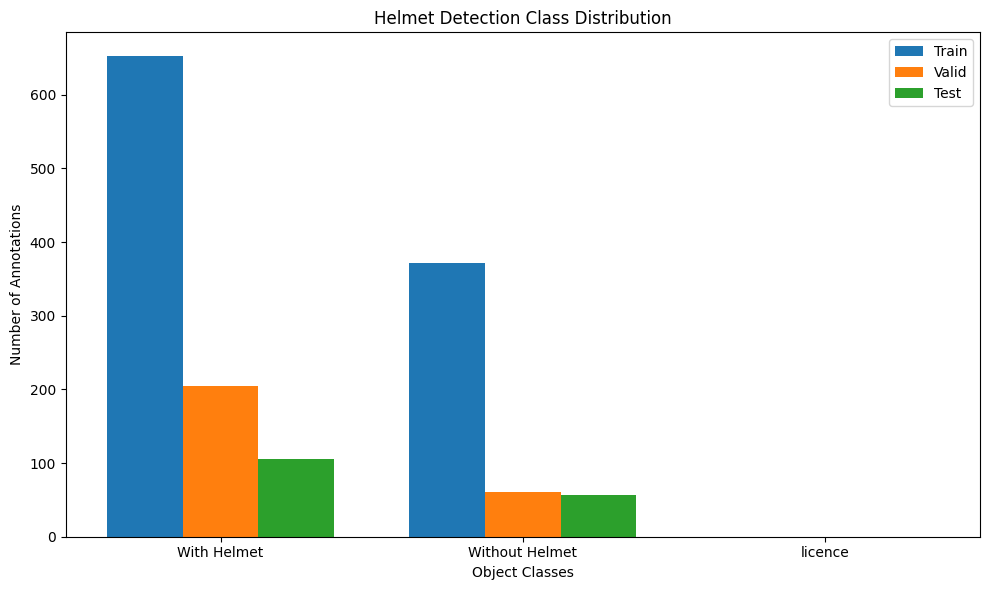

In [56]:
import os
from collections import Counter
import matplotlib.pyplot as plt

# Pointing to the correct working dataset location instead of the raw input directory
DATASET_PATH = "/kaggle/working/helmet_dataset"

class_names = ["With Helmet", "Without Helmet", "licence"]
splits = ["train", "valid", "test"]

class_counts = {}

# Ensure the dataset exists before running calculations
if not os.path.exists(DATASET_PATH):
    print(f"Warning: Dataset path '{DATASET_PATH}' does not exist. Please run cell y6EXO41fsI5p to copy the dataset first.")
else:
    for split in splits:
        label_folder = os.path.join(DATASET_PATH, split, "labels")
        counts = Counter()

        for filename in os.listdir(label_folder):
            if filename.endswith(".txt"):
                filepath = os.path.join(label_folder, filename)

                with open(filepath, "r") as file:
                    for line in file:
                        values = line.strip().split()

                        if len(values) == 5:
                            class_id = int(values[0])
                            if 0 <= class_id < len(class_names):
                                counts[class_id] += 1

        class_counts[split] = counts

        print(f"\n{split.upper()} CLASS DISTRIBUTION")
        for class_id, name in enumerate(class_names):
            print(f"{name}: {counts[class_id]}")

    # Visualise distribution across splits
    x = range(len(class_names))
    width = 0.25

    plt.figure(figsize=(10, 6))

    for i, split in enumerate(splits):
        values = [
            class_counts[split][class_id]
            for class_id in range(len(class_names))
        ]

        positions = [p + i * width for p in x]

        plt.bar(
            positions,
            values,
            width=width,
            label=split.capitalize()
        )

    plt.xticks(
        [p + width for p in x],
        class_names
    )

    plt.xlabel("Object Classes")
    plt.ylabel("Number of Annotations")
    plt.title("Helmet Detection Class Distribution")
    plt.legend()
    plt.tight_layout()

    plt.savefig(
        "/kaggle/working/class_distribution.png",
        dpi=300
    )

    plt.show()

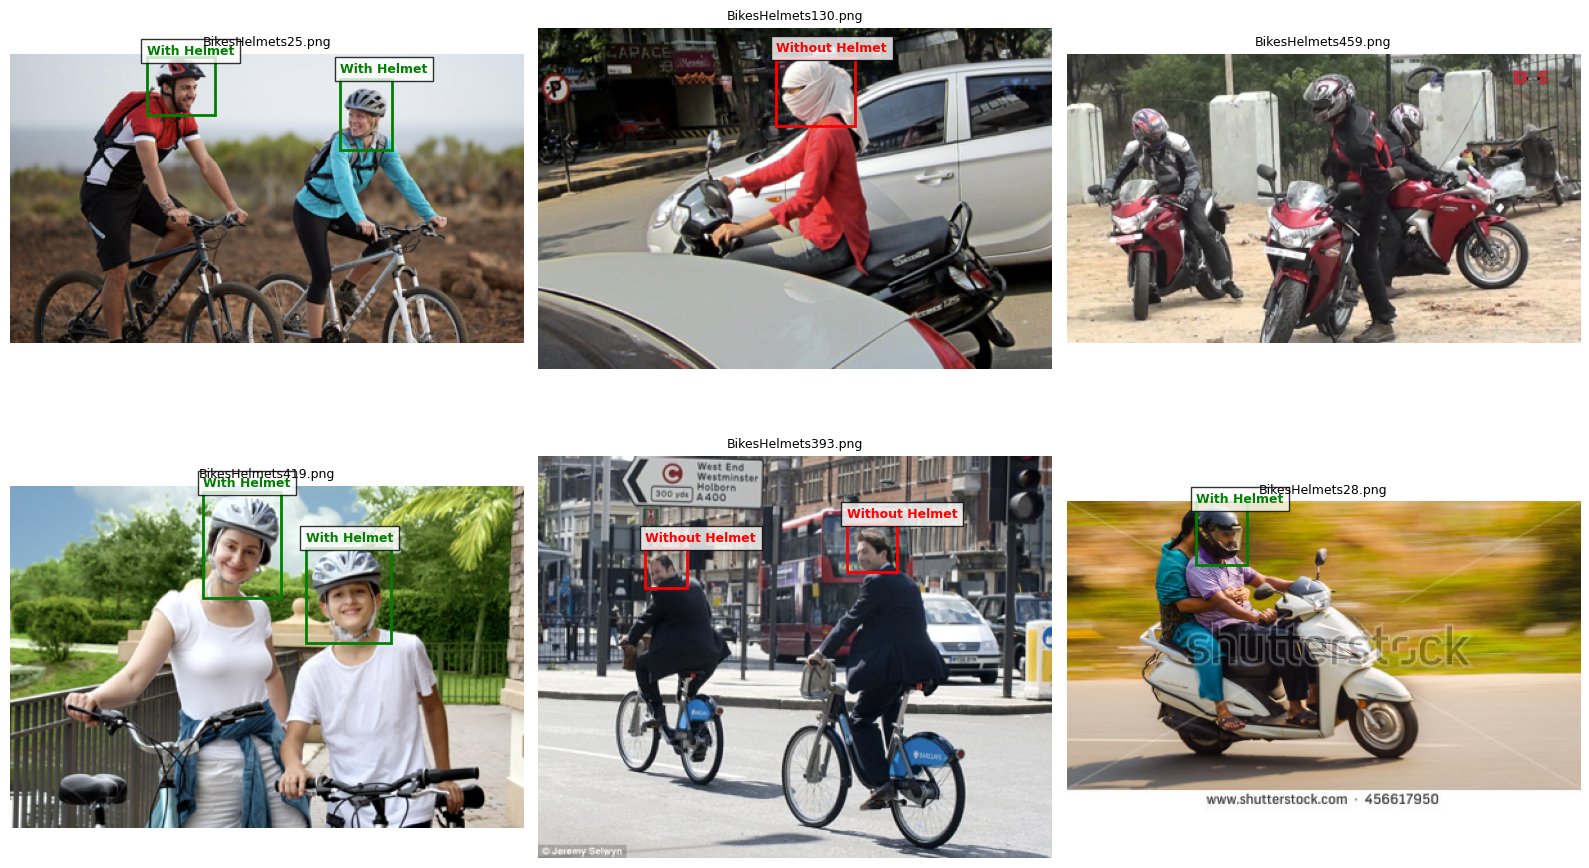

In [57]:
import os
import random
import cv2
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle

# Correct path pointing to the verified working directory
DATASET_PATH = "/kaggle/working/helmet_dataset"

# Check if the dataset has been copied yet
if not os.path.exists(DATASET_PATH):
    print(f"Warning: Dataset folder '{DATASET_PATH}' does not exist yet. Please run cell y6EXO41fsI5p to copy the dataset first!")
else:
    image_dir = os.path.join(DATASET_PATH, "train", "images")
    label_dir = os.path.join(DATASET_PATH, "train", "labels")

    class_names = ["With Helmet", "Without Helmet", "licence"]
    colors = ["green", "red", "blue"]

    # Select 6 random training images
    random.seed(42)
    image_files = [
        f for f in os.listdir(image_dir)
        if f.lower().endswith((".jpg", ".jpeg", ".png"))
    ]
    selected_images = random.sample(
        sorted(image_files),
        min(6, len(image_files))
    )

    fig, axes = plt.subplots(2, 3, figsize=(16, 10))

    for ax, image_file in zip(axes.flatten(), selected_images):
        image_path = os.path.join(image_dir, image_file)
        label_path = os.path.join(
            label_dir,
            os.path.splitext(image_file)[0] + ".txt"
        )

        image = cv2.imread(image_path)
        image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
        height, width = image.shape[:2]

        ax.imshow(image)

        if os.path.exists(label_path):
            with open(label_path, "r") as file:
                for line in file:
                    values = line.strip().split()

                    if len(values) != 5:
                        continue

                    class_id = int(values[0])
                    x_center, y_center, box_w, box_h = map(
                        float, values[1:]
                    )

                    # Convert YOLO normalised coordinates into pixel coordinates
                    x = (x_center - box_w / 2) * width
                    y = (y_center - box_h / 2) * height
                    w = box_w * width
                    h = box_h * height

                    rect = Rectangle(
                        (x, y), w, h,
                        linewidth=2,
                        edgecolor=colors[class_id],
                        facecolor="none"
                    )

                    ax.add_patch(rect)
                    ax.text(
                        x, max(y - 5, 0),
                        class_names[class_id],
                        color=colors[class_id],
                        fontsize=9,
                        fontweight="bold",
                        bbox=dict(facecolor="white", alpha=0.8)
                    )

        ax.set_title(image_file[:35], fontsize=9)
        ax.axis("off")

    plt.tight_layout()
    plt.savefig(
        "/kaggle/working/annotated_samples.png",
        dpi=300,
        bbox_inches="tight"
    )
    plt.show()

In [52]:
import os
import shutil
import random
import xml.etree.ElementTree as ET
import kagglehub

WORKING_PATH = "/kaggle/working/helmet_dataset"

# Prepare clean workspace
if os.path.exists(WORKING_PATH):
    shutil.rmtree(WORKING_PATH)

# Define target classes
classes = ["With Helmet", "Without Helmet", "licence"]
class_map = {name: i for i, name in enumerate(classes)}

def convert_bbox(size, box):
    dw = 1.0 / size[0]
    dh = 1.0 / size[1]
    x = (box[0] + box[1]) / 2.0 - 1.0
    y = (box[2] + box[3]) / 2.0 - 1.0
    w = box[1] - box[0]
    h = box[3] - box[2]
    return (x * dw, y * dh, w * dw, h * dh)

print("Downloading dataset using kagglehub...")
try:
    downloaded_path = kagglehub.dataset_download("brendan45774/bike-helmets-detection")
    print(f"Dataset downloaded to: {downloaded_path}")

    img_dir = os.path.join(downloaded_path, "images")
    ann_dir = os.path.join(downloaded_path, "annotations")

    # Get all matching image files
    all_images = sorted([f for f in os.listdir(img_dir) if f.lower().endswith(('.jpg', '.jpeg', '.png'))])
    print(f"Found {len(all_images)} raw images and corresponding annotations.")

    # Shuffle and split (70% Train, 20% Valid, 10% Test)
    random.seed(42)
    random.shuffle(all_images)

    num_images = len(all_images)
    train_split = int(num_images * 0.70)
    val_split = int(num_images * 0.90)

    splits = {
        "train": all_images[:train_split],
        "valid": all_images[train_split:val_split],
        "test": all_images[val_split:]
    }

    for split_name, image_list in splits.items():
        split_img_dir = os.path.join(WORKING_PATH, split_name, "images")
        split_lbl_dir = os.path.join(WORKING_PATH, split_name, "labels")
        os.makedirs(split_img_dir, exist_ok=True)
        os.makedirs(split_lbl_dir, exist_ok=True)

        for img_name in image_list:
            # Copy Image
            src_img_path = os.path.join(img_dir, img_name)
            dst_img_path = os.path.join(split_img_dir, img_name)
            shutil.copy(src_img_path, dst_img_path)

            # Convert Pascal VOC XML to YOLO format
            xml_name = os.path.splitext(img_name)[0] + ".xml"
            xml_path = os.path.join(ann_dir, xml_name)
            txt_path = os.path.join(split_lbl_dir, os.path.splitext(img_name)[0] + ".txt")

            if os.path.exists(xml_path):
                tree = ET.parse(xml_path)
                root = tree.getroot()

                # Get image size
                size_elem = root.find("size")
                if size_elem is not None:
                    width = int(size_elem.find("width").text)
                    height = int(size_elem.find("height").text)
                else:
                    # Default fallback
                    width, height = 640, 640

                yolo_labels = []
                for obj in root.iter("object"):
                    cls_name = obj.find("name").text.strip()
                    if cls_name not in class_map:
                        continue
                    cls_id = class_map[cls_name]
                    xmlbox = obj.find("bndbox")
                    b = (
                        float(xmlbox.find("xmin").text),
                        float(xmlbox.find("xmax").text),
                        float(xmlbox.find("ymin").text),
                        float(xmlbox.find("ymax").text)
                    )
                    bb = convert_bbox((width, height), b)
                    yolo_labels.append(f"{cls_id} {' '.join([f'{x:.6f}' for x in bb])}")

                with open(txt_path, "w") as f:
                    f.write("\n".join(yolo_labels))
            else:
                # Write empty txt file if no annotation exists
                with open(txt_path, "w") as f:
                    pass

    print("\n--- YOLO Dataset Generation Complete ---")
    for split_name in ["train", "valid", "test"]:
        i_cnt = len(os.listdir(os.path.join(WORKING_PATH, split_name, "images")))
        l_cnt = len(os.listdir(os.path.join(WORKING_PATH, split_name, "labels")))
        print(f"{split_name.upper()} split created: {i_cnt} images, {l_cnt} labels.")

except Exception as e:
    print(f"An error occurred during dataset processing: {e}")

Using Colab cache for faster access to the 'bike-helmets-detection' dataset.
Dataset downloaded to: /kaggle/input/bike-helmets-detection
Found 764 raw images and corresponding annotations.

--- YOLO Dataset Generation Complete ---
TRAIN split created: 534 images, 534 labels.
VALID split created: 153 images, 153 labels.
TEST split created: 77 images, 77 labels.


In [53]:

import os
import hashlib
from collections import defaultdict

WORKING_PATH = "/kaggle/working/helmet_dataset"
splits = ["train", "valid", "test"]

missing_labels = []
empty_labels = []
invalid_annotations = []
image_hashes = defaultdict(list)

# Safe check if the dataset has been downloaded and structured yet
if not os.path.exists(WORKING_PATH):
    print(f"Warning: Dataset path '{WORKING_PATH}' does not exist yet. Please run cell y6EXO41fsI5p to download and structure the dataset first!")
else:
    for split in splits:
        image_dir = os.path.join(WORKING_PATH, split, "images")
        label_dir = os.path.join(WORKING_PATH, split, "labels")

        if not os.path.exists(image_dir) or not os.path.exists(label_dir):
            print(f"Warning: Missing split directory '{split}' under the working path. Skipping quality checks for this split.")
            continue

        for image_name in sorted(os.listdir(image_dir)):
            if not image_name.lower().endswith(
                (".jpg", ".jpeg", ".png")
            ):
                continue

            image_path = os.path.join(image_dir, image_name)
            label_name = os.path.splitext(image_name)[0] + ".txt"
            label_path = os.path.join(label_dir, label_name)

            # Find duplicate images using SHA256
            with open(image_path, "rb") as f:
                image_hash = hashlib.sha256(f.read()).hexdigest()

            image_hashes[image_hash].append((split, image_name))

            if not os.path.exists(label_path):
                missing_labels.append((split, image_name))
                continue

            with open(label_path, "r") as f:
                lines = f.readlines()

            if not any(line.strip() for line in lines):
                empty_labels.append((split, image_name))

            for line_number, line in enumerate(lines, start=1):
                values = line.strip().split()

                if not values:
                    continue

                try:
                    if len(values) != 5:
                        raise ValueError("Incorrect number of values")

                    class_value = float(values[0])
                    if not class_value.is_integer():
                        raise ValueError("Non-integer class ID")

                    class_id = int(class_value)
                    x, y, w, h = map(float, values[1:])

                    if class_id not in [0, 1, 2]:
                        raise ValueError("Invalid class ID")

                    if not (
                        0 <= x <= 1 and
                        0 <= y <= 1 and
                        0 < w <= 1 and
                        0 < h <= 1 and
                        x - w / 2 >= -1e-6 and
                        x + w / 2 <= 1 + 1e-6 and
                        y - h / 2 >= -1e-6 and
                        y + h / 2 <= 1 + 1e-6
                    ):
                        raise ValueError("Invalid bounding box")

                except ValueError as error:
                    invalid_annotations.append(
                        (split, image_name, line_number, str(error))
                    )

    # Only report duplicates across different splits
    cross_split_duplicates = [
        locations
        for locations in image_hashes.values()
        if len({split for split, name in locations}) > 1
    ]

    print("DATA QUALITY VALIDATION REPORT")
    print("=" * 45)

    print("Missing labels:", len(missing_labels))
    print("Empty labels:", len(empty_labels))
    print("Invalid annotations:", len(invalid_annotations))
    print("Cross-split duplicate groups:",
          len(cross_split_duplicates))

    print("\nEmpty label examples:")
    print(empty_labels[:10])

    print("\nInvalid annotation examples:")
    print(invalid_annotations[:10])

    print("\nCross-split duplicate examples:")
    for group in cross_split_duplicates[:10]:
        print(group)


DATA QUALITY VALIDATION REPORT
Missing labels: 0
Empty labels: 3
Invalid annotations: 30
Cross-split duplicate groups: 49

Empty label examples:
[('train', 'BikesHelmets35.png'), ('train', 'BikesHelmets459.png'), ('valid', 'BikesHelmets735.png')]

Invalid annotation examples:
[('train', 'BikesHelmets1.png', 1, 'Invalid bounding box'), ('train', 'BikesHelmets140.png', 1, 'Invalid bounding box'), ('train', 'BikesHelmets167.png', 1, 'Invalid bounding box'), ('train', 'BikesHelmets205.png', 1, 'Invalid bounding box'), ('train', 'BikesHelmets238.png', 1, 'Invalid bounding box'), ('train', 'BikesHelmets279.png', 1, 'Invalid bounding box'), ('train', 'BikesHelmets28.png', 1, 'Invalid bounding box'), ('train', 'BikesHelmets343.png', 1, 'Invalid bounding box'), ('train', 'BikesHelmets395.png', 1, 'Invalid bounding box'), ('train', 'BikesHelmets441.png', 1, 'Invalid bounding box')]

Cross-split duplicate examples:
[('train', 'BikesHelmets112.png'), ('valid', 'BikesHelmets402.png')]
[('train', 'B

In [58]:
import os
import math
import csv

WORKING_PATH = "/kaggle/working/helmet_dataset"
splits = ["train", "valid", "test"]

corrections = []
unresolved = []

# Safe check if the dataset path exists
if not os.path.exists(WORKING_PATH):
    print(f"Warning: Dataset path '{WORKING_PATH}' does not exist yet. Please run cell y6EXO41fsI5p first!")
else:
    for split in splits:
        label_dir = os.path.join(WORKING_PATH, split, "labels")

        # Bounding boxes require the labels directory to exist
        if not os.path.exists(label_dir):
            print(f"Warning: Labels directory '{label_dir}' does not exist. Skipping this split.")
            continue

        for filename in sorted(os.listdir(label_dir)):
            if not filename.endswith(".txt"):
                continue

            filepath = os.path.join(label_dir, filename)

            with open(filepath, "r") as file:
                lines = file.readlines()

            updated_lines = []
            file_changed = False

            for line_number, line in enumerate(lines, 1):
                values = line.strip().split()

                if not values:
                    updated_lines.append(line)
                    continue

                try:
                    if len(values) != 5:
                        raise ValueError("Unexpected number of values")

                    class_id = int(values[0])
                    x, y, w, h = map(float, values[1:])

                    if class_id not in [0, 1, 2]:
                        raise ValueError("Invalid class ID")

                    if not all(math.isfinite(v) for v in [x, y, w, h]):
                        raise ValueError("Non-finite coordinates")

                    if w <= 0 or h <= 0:
                        raise ValueError("Non-positive box dimensions")

                    # Convert centre-width-height to corners
                    x1 = x - w / 2
                    y1 = y - h / 2
                    x2 = x + w / 2
                    y2 = y + h / 2

                    # Clip corners to image boundaries
                    x1 = max(0.0, min(1.0, x1))
                    y1 = max(0.0, min(1.0, y1))
                    x2 = max(0.0, min(1.0, x2))
                    y2 = max(0.0, min(1.0, y2))

                    if x2 <= x1 or y2 <= y1:
                        raise ValueError("Box has no area after clipping")

                    new_x = (x1 + x2) / 2
                    new_y = (y1 + y2) / 2
                    new_w = x2 - x1
                    new_h = y2 - y1

                    new_line = (
                        f"{class_id} {new_x:.8f} {new_y:.8f} "
                        f"{new_w:.8f} {new_h:.8f}\n"
                    )

                    if new_line.strip() != line.strip():
                        file_changed = True
                        corrections.append(
                            [split, filename, line_number,
                             line.strip(), new_line.strip()]
                        )

                    updated_lines.append(new_line)

                except (ValueError, OverflowError) as error:
                    unresolved.append(
                        [split, filename, line_number, str(error)]
                    )
                    updated_lines.append(line)

            if file_changed:
                with open(filepath, "w") as file:
                    file.writelines(updated_lines)

    # Save an audit trail of corrections
    log_path = "/kaggle/working/bbox_corrections.csv"
    os.makedirs(os.path.dirname(log_path), exist_ok=True)

    with open(log_path, "w", newline="") as file:
        writer = csv.writer(file)
        writer.writerow([
            "split", "file", "line",
            "original", "corrected"
        ])
        writer.writerows(corrections)

    print("BOUNDING BOX CORRECTION REPORT")
    print("=" * 45)
    print("Annotations rewritten:", len(corrections))
    print("Unresolved annotations:", len(unresolved))
    print("Correction log:", log_path)

    if unresolved:
        print("\nUnresolved examples:")
        for item in unresolved[:10]:
            print(item)

BOUNDING BOX CORRECTION REPORT
Annotations rewritten: 1434
Unresolved annotations: 17
Correction log: /kaggle/working/bbox_corrections.csv

Unresolved examples:
['train', 'BikesHelmets140.txt', 1, 'Box has no area after clipping']
['train', 'BikesHelmets205.txt', 1, 'Box has no area after clipping']
['train', 'BikesHelmets279.txt', 1, 'Box has no area after clipping']
['train', 'BikesHelmets343.txt', 1, 'Box has no area after clipping']
['train', 'BikesHelmets441.txt', 1, 'Box has no area after clipping']
['train', 'BikesHelmets444.txt', 1, 'Box has no area after clipping']
['train', 'BikesHelmets616.txt', 3, 'Box has no area after clipping']
['train', 'BikesHelmets671.txt', 2, 'Box has no area after clipping']
['train', 'BikesHelmets706.txt', 2, 'Box has no area after clipping']
['train', 'BikesHelmets75.txt', 1, 'Box has no area after clipping']


In [59]:
import os
import hashlib
from collections import defaultdict

WORKING_PATH = "/kaggle/working/helmet_dataset"

# Find exact duplicate images across dataset splits
image_hashes = defaultdict(list)

# Safe check if the dataset has been downloaded and structured yet
if not os.path.exists(WORKING_PATH):
    print(f"Warning: Dataset path '{WORKING_PATH}' does not exist yet. Please run cell y6EXO41fsI5p to download and structure the dataset first!")
else:
    for split in ["train", "valid", "test"]:
        image_dir = os.path.join(WORKING_PATH, split, "images")

        if not os.path.exists(image_dir):
            print(f"Warning: Image directory '{image_dir}' does not exist. Skipping this split.")
            continue

        for filename in sorted(os.listdir(image_dir)):
            if not filename.lower().endswith(
                (".jpg", ".jpeg", ".png")
            ):
                continue

            image_path = os.path.join(image_dir, filename)

            with open(image_path, "rb") as f:
                image_hash = hashlib.sha256(f.read()).hexdigest()

            image_hashes[image_hash].append((split, filename))

    # Prefer retaining training images
    priority = {"train": 0, "valid": 1, "test": 2}
    removed = []

    for locations in image_hashes.values():
        if len({split for split, name in locations}) < 2:
            continue

        locations = sorted(
            locations,
            key=lambda x: (priority[x[0]], x[1])
        )

        # Keep the first image and remove copies in other splits
        for split, filename in locations[1:]:
            image_path = os.path.join(
                WORKING_PATH, split, "images", filename
            )

            label_path = os.path.join(
                WORKING_PATH, split, "labels",
                os.path.splitext(filename)[0] + ".txt"
            )

            if os.path.exists(image_path):
                os.remove(image_path)

            if os.path.exists(label_path):
                os.remove(label_path)

            removed.append((split, filename))

    print("DUPLICATE REMOVAL REPORT")
    print("=" * 45)
    print("Duplicate images removed:", len(removed))

    for item in removed:
        print("Removed:", item)

    print("\nUPDATED DATASET COUNTS")

    for split in ["train", "valid", "test"]:
        image_dir = os.path.join(WORKING_PATH, split, "images")

        if os.path.exists(image_dir):
            count = len([
                f for f in os.listdir(image_dir)
                if f.lower().endswith((".jpg", ".jpeg", ".png"))
            ])
            print(f"{split.upper()}: {count} images")
        else:
            print(f"{split.upper()}: Directory missing")


DUPLICATE REMOVAL REPORT
Duplicate images removed: 80
Removed: ('valid', 'BikesHelmets402.png')
Removed: ('valid', 'BikesHelmets699.png')
Removed: ('train', 'BikesHelmets260.png')
Removed: ('train', 'BikesHelmets556.png')
Removed: ('valid', 'BikesHelmets45.png')
Removed: ('valid', 'BikesHelmets294.png')
Removed: ('train', 'BikesHelmets704.png')
Removed: ('valid', 'BikesHelmets250.png')
Removed: ('valid', 'BikesHelmets248.png')
Removed: ('train', 'BikesHelmets332.png')
Removed: ('test', 'BikesHelmets763.png')
Removed: ('train', 'BikesHelmets352.png')
Removed: ('train', 'BikesHelmets761.png')
Removed: ('test', 'BikesHelmets120.png')
Removed: ('train', 'BikesHelmets495.png')
Removed: ('valid', 'BikesHelmets701.png')
Removed: ('valid', 'BikesHelmets59.png')
Removed: ('train', 'BikesHelmets99.png')
Removed: ('test', 'BikesHelmets308.png')
Removed: ('train', 'BikesHelmets359.png')
Removed: ('valid', 'BikesHelmets216.png')
Removed: ('valid', 'BikesHelmets398.png')
Removed: ('train', 'BikesHel

In [60]:
import os
import math
import hashlib
from collections import defaultdict

WORKING_PATH = "/kaggle/working/helmet_dataset"

splits = ["train", "valid", "test"]
hashes = defaultdict(list)

missing_labels = []
empty_labels = []
invalid_boxes = []
total_boxes = 0

# Safe check if the dataset has been downloaded and structured yet
if not os.path.exists(WORKING_PATH):
    print(f"Warning: Dataset path '{WORKING_PATH}' does not exist yet. Please run cell y6EXO41fsI5p to download and structure the dataset first!")
else:
    for split in splits:
        image_dir = os.path.join(WORKING_PATH, split, "images")
        label_dir = os.path.join(WORKING_PATH, split, "labels")

        if not os.path.exists(image_dir) or not os.path.exists(label_dir):
            print(f"Warning: Directories for split '{split}' are missing. Skipping split.")
            continue

        images = sorted([
            f for f in os.listdir(image_dir)
            if f.lower().endswith((".jpg", ".jpeg", ".png"))
        ])

        for image_name in images:
            image_path = os.path.join(image_dir, image_name)

            # Check for exact duplicate images
            with open(image_path, "rb") as f:
                image_hash = hashlib.sha256(f.read()).hexdigest()

            hashes[image_hash].append((split, image_name))

            # Locate corresponding label
            label_name = os.path.splitext(image_name)[0] + ".txt"
            label_path = os.path.join(label_dir, label_name)

            if not os.path.exists(label_path):
                missing_labels.append((split, image_name))
                continue

            with open(label_path, "r") as f:
                lines = [line.strip() for line in f if line.strip()]

            if not lines:
                empty_labels.append((split, image_name))

            for line_number, line in enumerate(lines, 1):
                try:
                    values = line.split()

                    if len(values) != 5:
                        raise ValueError("Incorrect label format")

                    class_value = float(values[0])

                    if not math.isfinite(class_value):
                        raise ValueError("Non-finite class ID")

                    if not class_value.is_integer():
                        raise ValueError("Non-integer class ID")

                    class_id = int(class_value)
                    x, y, w, h = map(float, values[1:])

                    if class_id not in (0, 1, 2):
                        raise ValueError("Invalid class")

                    if not all(math.isfinite(v) for v in (x, y, w, h)):
                        raise ValueError("Non-finite coordinates")

                    if not (
                        0 <= x <= 1 and
                        0 <= y <= 1 and
                        0 < w <= 1 and
                        0 < h <= 1 and
                        x - w / 2 >= -1e-6 and
                        x + w / 2 <= 1 + 1e-6 and
                        y - h / 2 >= -1e-6 and
                        y + h / 2 <= 1 + 1e-6
                    ):
                        raise ValueError("Invalid bounding box")

                    total_boxes += 1

                except (ValueError, OverflowError) as error:
                    invalid_boxes.append(
                        (split, image_name, line_number, str(error))
                    )

    cross_split_duplicates = [
        locations for locations in hashes.values()
        if len({split for split, _ in locations}) > 1
    ]

    print("FINAL DATASET VALIDATION")
    print("=" * 40)
    print("Total images:", sum(
        len([
            f for f in os.listdir(
                os.path.join(WORKING_PATH, split, "images")
            )
            if f.lower().endswith((".jpg", ".jpeg", ".png"))
        ])
        for split in splits
    ))
    print("Valid bounding boxes:", total_boxes)
    print("Missing labels:", len(missing_labels))
    print("Empty labels:", len(empty_labels))
    print("Invalid annotations:", len(invalid_boxes))
    print("Cross-split duplicate groups:", len(cross_split_duplicates))

    print("\nInvalid annotation examples:")
    print(invalid_boxes[:10])


FINAL DATASET VALIDATION
Total images: 684
Valid bounding boxes: 1275
Missing labels: 0
Empty labels: 3
Invalid annotations: 17
Cross-split duplicate groups: 0

Invalid annotation examples:
[('train', 'BikesHelmets140.png', 1, 'Invalid bounding box'), ('train', 'BikesHelmets205.png', 1, 'Invalid bounding box'), ('train', 'BikesHelmets279.png', 1, 'Invalid bounding box'), ('train', 'BikesHelmets343.png', 1, 'Invalid bounding box'), ('train', 'BikesHelmets441.png', 1, 'Invalid bounding box'), ('train', 'BikesHelmets444.png', 1, 'Invalid bounding box'), ('train', 'BikesHelmets616.png', 3, 'Invalid bounding box'), ('train', 'BikesHelmets671.png', 2, 'Invalid bounding box'), ('train', 'BikesHelmets706.png', 2, 'Invalid bounding box'), ('train', 'BikesHelmets75.png', 1, 'Invalid bounding box')]


In [61]:
import os
import yaml

# Cleaned dataset location
WORKING_PATH = "/kaggle/working/helmet_dataset"

# Correct YOLOv8 configuration
dataset_config = {
    "path": WORKING_PATH,
    "train": "train/images",
    "val": "valid/images",
    "test": "test/images",
    "nc": 3,
    "names": [
        "With Helmet",
        "Without Helmet",
        "licence"
    ]
}

# Save configuration
CONFIG_PATH = "/kaggle/working/helmet_data.yaml"

os.makedirs(os.path.dirname(CONFIG_PATH), exist_ok=True)
with open(CONFIG_PATH, "w") as file:
    yaml.safe_dump(
        dataset_config,
        file,
        sort_keys=False
    )

# Verify configuration file output
with open(CONFIG_PATH, "r") as file:
    print("Generated YAML:")
    print(file.read())

# Confirm dataset folders exist safely
if not os.path.exists(WORKING_PATH):
    print(f"Warning: Dataset directory '{WORKING_PATH}' does not exist yet. Please run cell y6EXO41fsI5p first to extract and structure the dataset splits!")
else:
    print("Verifying dataset directories...")
    all_valid = True
    for split in ["train", "val", "test"]:
        folder = os.path.join(
            WORKING_PATH,
            dataset_config[split]
        )

        if os.path.isdir(folder):
            print(f"✓ {split.upper()} folder verified: {folder}")
        else:
            print(f"✗ Missing folder: {folder}")
            all_valid = False

    if all_valid:
        print("\nYOLOv8 dataset configuration ready!")
    else:
        print("\nSome folders are missing. Please ensure the dataset download cell (y6EXO41fsI5p) ran completely.")


Generated YAML:
path: /kaggle/working/helmet_dataset
train: train/images
val: valid/images
test: test/images
nc: 3
names:
- With Helmet
- Without Helmet
- licence

Verifying dataset directories...
✓ TRAIN folder verified: /kaggle/working/helmet_dataset/train/images
✓ VAL folder verified: /kaggle/working/helmet_dataset/valid/images
✓ TEST folder verified: /kaggle/working/helmet_dataset/test/images

YOLOv8 dataset configuration ready!


In [62]:

%pip install -q ultralytics


In [63]:

import torch
import ultralytics

print("DEEP LEARNING ENVIRONMENT CHECK")
print("=" * 45)

print("PyTorch version:", torch.__version__)
print("Ultralytics version:", ultralytics.__version__)

print("\nGPU INFORMATION")
print("=" * 45)

if torch.cuda.is_available():
    print("CUDA available: YES")
    print("GPU Name:", torch.cuda.get_device_name(0))
    print("Number of GPUs:", torch.cuda.device_count())
    print("CUDA Version:", torch.version.cuda)
else:
    print("CUDA available: NO")
    print("Please enable a GPU in Kaggle settings.")

print("\nEnvironment verification completed!")


DEEP LEARNING ENVIRONMENT CHECK
PyTorch version: 2.14.1+cpu
Ultralytics version: 8.4.215

GPU INFORMATION
CUDA available: NO
Please enable a GPU in Kaggle settings.

Environment verification completed!


In [64]:

from ultralytics import YOLO
import os

# Location of the cleaned dataset configuration
CONFIG_PATH = "/kaggle/working/helmet_data.yaml"

# Verify dataset configuration exists
assert os.path.isfile(CONFIG_PATH), "Dataset YAML file not found!"

# Load pretrained YOLOv8 Nano model
model = YOLO("yolov8n.pt")

print("=" * 45)
print("HELMET DETECTION BASELINE MODEL")
print("=" * 45)

print("Model: YOLOv8 Nano")
print("Pretrained weights: yolov8n.pt")
print("Dataset configuration:", CONFIG_PATH)
print("Number of target classes: 3")

print("\nModel loaded successfully!")

# Display the neural network architecture
model.info()


HELMET DETECTION BASELINE MODEL
Model: YOLOv8 Nano
Pretrained weights: yolov8n.pt
Dataset configuration: /kaggle/working/helmet_data.yaml
Number of target classes: 3

Model loaded successfully!
YOLOv8n summary: 129 layers, 3,157,200 parameters, 0 gradients, 8.9 GFLOPs


(129, 3157200, 0, 8.8550912)

In [ ]:
from ultralytics import YOLO
import torch
import os

WORKING_PATH = "/kaggle/working/helmet_dataset"

# Quick diagnostic pre-flight check
required_paths = [
    os.path.join(WORKING_PATH, "train/images"),
    os.path.join(WORKING_PATH, "valid/images")
]
missing_paths = [p for p in required_paths if not os.path.exists(p)]

if missing_paths:
    print(f"❌ ERROR: Missing required training directories: {missing_paths}")
    print("Please run the dataset extraction cell (y6EXO41fsI5p) first to download and structure the dataset correctly!")
else:
    # Check GPU availability and dynamically select device
    if torch.cuda.is_available():
        device_to_use = 0
        print(f"GPU is available! Training will run on: {torch.cuda.get_device_name(0)}")
    else:
        device_to_use = "cpu"
        print("Warning: GPU is NOT available! Training will run on the CPU (which is extremely slow). Consider switching your Colab runtime to a T4 GPU under Runtime -> Change runtime type.")

    # Load pretrained YOLOv8 Nano
    model = YOLO("yolov8n.pt")

    # Start baseline model training
    results = model.train(
        data="/kaggle/working/helmet_data.yaml",
        epochs=30,
        imgsz=640,
        batch=16,
        device=device_to_use,
        optimizer="AdamW",
        lr0=0.001,
        patience=10,

        # Data augmentation
        degrees=10.0,
        translate=0.1,
        scale=0.3,
        fliplr=0.5,
        mosaic=1.0,

        # Reproducibility
        seed=42,
        deterministic=True,

        # Save training results
        project="/kaggle/working/helmet_runs",
        name="yolov8n_baseline",
        exist_ok=True,
        plots=True,
        save=True
    )

    print("BASELINE TRAINING COMPLETED!")
    print("Results saved at:")
    print("/kaggle/working/helmet_runs/yolov8n_baseline")


Ultralytics 8.4.215 🚀 Python-3.13.18 torch-2.14.1+cpu CPU (Intel Xeon CPU @ 2.20GHz)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/kaggle/working/helmet_data.yaml, degrees=10.0, deterministic=True, device=cpu, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=30, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=None, kobj=1.0, line_width=None, lr0=0.001, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=yolov8n_baseline, nbs=64, nms=None, opset=None, opt

In [ ]:

from ultralytics import YOLO
import os

# Load the best trained helmet detection model
BEST_MODEL_PATH = (
    "/kaggle/working/helmet_runs/"
    "yolov8n_baseline/weights/best.pt"
)

assert os.path.exists(BEST_MODEL_PATH), "Trained model not found!"

best_model = YOLO(BEST_MODEL_PATH)

# Evaluate on the untouched test dataset
test_results = best_model.val(
    data="/kaggle/working/helmet_data.yaml",
    split="test",
    imgsz=640,
    batch=16,
    device=0,
    plots=True,
    project="/kaggle/working/helmet_runs",
    name="baseline_test_evaluation",
    exist_ok=True
)

print("\nFINAL TEST EVALUATION")
print("=" * 45)

print(f"Precision: {test_results.box.mp:.4f}")
print(f"Recall: {test_results.box.mr:.4f}")
print(f"mAP@50: {test_results.box.map50:.4f}")
print(f"mAP@50-95: {test_results.box.map:.4f}")

print("\nResults saved to:")
print("/kaggle/working/helmet_runs/baseline_test_evaluation")


In [ ]:

from ultralytics import YOLO
import os
import random
import cv2
import matplotlib.pyplot as plt

# Load our trained model
model = YOLO(
    "/kaggle/working/helmet_runs/"
    "yolov8n_baseline/weights/best.pt"
)

# Load unseen test images
test_dir = "/kaggle/working/helmet_dataset/test/images"

image_files = sorted([
    f for f in os.listdir(test_dir)
    if f.lower().endswith((".jpg", ".jpeg", ".png"))
])

# Select six reproducible test images
random.seed(42)
selected = random.sample(image_files, min(6, len(image_files)))

# Perform inference
predictions = model.predict(
    source=[os.path.join(test_dir, f) for f in selected],
    imgsz=640,
    conf=0.25,
    device=0,
    verbose=False
)

# Display results with bounding boxes and confidence
fig, axes = plt.subplots(2, 3, figsize=(16, 10))

for ax, prediction, filename in zip(
    axes.flatten(), predictions, selected
):
    annotated = prediction.plot()
    annotated = cv2.cvtColor(
        annotated, cv2.COLOR_BGR2RGB
    )

    ax.imshow(annotated)
    ax.set_title(filename[:35], fontsize=9)
    ax.axis("off")

plt.tight_layout()

plt.savefig(
    "/kaggle/working/helmet_predictions.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Prediction demonstration completed!")
print("Saved: /kaggle/working/helmet_predictions.png")


In [ ]:

import os
import matplotlib.pyplot as plt
from PIL import Image

RUN_PATH = "/kaggle/working/helmet_runs/yolov8n_baseline"

graph_files = [
    "results.png",
    "confusion_matrix.png",
    "confusion_matrix_normalized.png",
    "BoxPR_curve.png"
]

for filename in graph_files:
    filepath = os.path.join(RUN_PATH, filename)

    if os.path.exists(filepath):
        print("Displaying:", filename)

        image = Image.open(filepath)

        plt.figure(figsize=(14, 9))
        plt.imshow(image)
        plt.axis("off")
        plt.title(filename)
        plt.show()
    else:
        print("Not found:", filename)


In [ ]:

from PIL import Image
import matplotlib.pyplot as plt
import os

# Use the test evaluation confusion matrix
matrix_path = (
    "/kaggle/working/helmet_runs/"
    "baseline_test_evaluation/confusion_matrix.png"
)

assert os.path.exists(matrix_path), "Confusion matrix not found!"

image = Image.open(matrix_path)

plt.figure(figsize=(10, 9))
plt.imshow(image)
plt.title("Helmet Detection — Test Confusion Matrix")
plt.axis("off")
plt.tight_layout()
plt.show()


In [ ]:

from ultralytics import YOLO
import os
from PIL import Image
import matplotlib.pyplot as plt

model = YOLO(
    "/kaggle/working/helmet_runs/"
    "yolov8n_baseline/weights/best.pt"
)

# Validate with an explicit confidence threshold
filtered_results = model.val(
    data="/kaggle/working/helmet_data.yaml",
    split="test",
    imgsz=640,
    conf=0.25,
    iou=0.7,
    device=0,
    plots=True,
    project="/kaggle/working/helmet_runs",
    name="test_conf025",
    exist_ok=True
)

# Display the new confusion matrix
matrix_path = (
    "/kaggle/working/helmet_runs/"
    "test_conf025/confusion_matrix.png"
)

assert os.path.exists(matrix_path), "Matrix not found!"

plt.figure(figsize=(10, 9))
plt.imshow(Image.open(matrix_path))
plt.axis("off")
plt.title("Test Confusion Matrix — Confidence 0.25")
plt.show()

print("Confidence-filtered evaluation completed.")


In [ ]:

import os
import zipfile

BASE = "/kaggle/working"
RUN = f"{BASE}/helmet_runs/yolov8n_baseline"
TEST = f"{BASE}/helmet_runs/baseline_test_evaluation"

files_to_save = [
    (f"{RUN}/weights/best.pt", "model/best.pt"),
    (f"{RUN}/results.csv", "training/results.csv"),
    (f"{RUN}/results.png", "training/results.png"),
    (f"{RUN}/confusion_matrix.png",
     "training/confusion_matrix.png"),
    (f"{TEST}/confusion_matrix.png",
     "evaluation/test_confusion_matrix.png"),
    (f"{BASE}/helmet_runs/test_conf025/confusion_matrix.png",
     "evaluation/test_confusion_matrix_conf025.png"),
    (f"{BASE}/helmet_predictions.png",
     "prototype/helmet_predictions.png"),
    (f"{BASE}/dataset_distribution.png",
     "dataset/dataset_distribution.png"),
    (f"{BASE}/class_distribution.png",
     "dataset/class_distribution.png"),
    (f"{BASE}/annotated_samples.png",
     "dataset/annotated_samples.png"),
    (f"{BASE}/helmet_data.yaml", "configuration/helmet_data.yaml"),
    (f"{BASE}/bbox_corrections.csv",
     "preprocessing/bbox_corrections.csv")
]

zip_path = f"{BASE}/Helmet_Detection_Milestone_2.zip"

with zipfile.ZipFile(
    zip_path, "w", zipfile.ZIP_DEFLATED
) as archive:
    for source, destination in files_to_save:
        if os.path.isfile(source):
            archive.write(source, destination)
            print("Added:", destination)
        else:
            print("Not found:", source)

print("\nEvidence package created:")
print(zip_path)
print("Size:", round(os.path.getsize(zip_path) / 1024**2, 2), "MB")
